# Regression notes

Notes and code for linear regression, using the real data: **shoe size (x)** predicting **height (y)** for the 222 students.

## Setup

In [1]:
# pandas for the data, numpy for maths, matplotlib and seaborn for plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

# scikit-learn: the regression model, the metrics, the train/test split and the baseline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor

# Load the cleaned data
df = pd.read_csv("../cleaned/dataminers_cleaner.csv")

# X is the input (shoe size). Double brackets, because scikit-learn wants a table, not a single column
X = df[["shoe_eu"]]

# y is what we want to predict (height)
y = df["height_cm"]

# A first look at the two columns
df[["shoe_eu", "height_cm"]].head()

,shoe_eu,height_cm
0,44.0,192.0
1,38.0,167.0
2,44.0,192.0
3,38.0,167.6
4,44.0,184.0


## Linear Regression

**What it is**

Linear regression fits a **straight line** to data, so that one variable $y$ can be predicted from another $x$. A scatter plot is how we *look* at the data and the line. The regression itself is the calculation behind the line. A positive slope indicates a direct relationship, while a negative slope shows an inverse relationship.

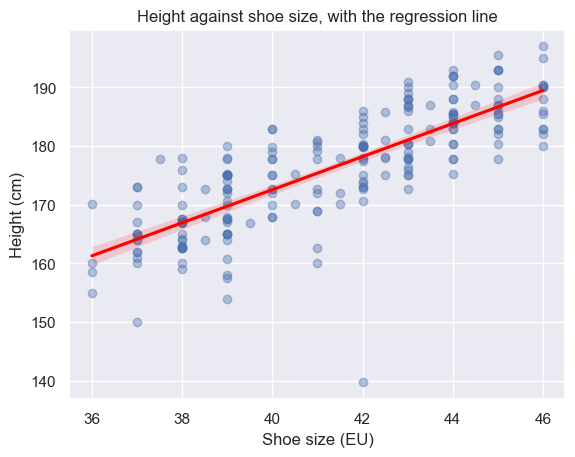

In [2]:
# The scatter plot with the fitted regression line (seaborn fits and draws it, but does not tell us the numbers)
sns.regplot(x=X["shoe_eu"], y=y, scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})

plt.title("Height against shoe size, with the regression line")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)");

**The formula:**

$$
y = b_1 \cdot x + b_2
$$

- $y$ is the output (dependent variable), $x$ is the input (independent variable).
- $b_1$ is the **slope**: how much $y$ changes when $x$ goes up by 1 unit.
- $b_2$ is the **intercept**: the value of $y$ when $x = 0$.

**In code:** `fit` finds the best slope and intercept, and scikit-learn stores them in the model: `coef_` is the slope $b_1$ (an array, because with several inputs there is one slope per input) and `intercept_` is the intercept $b_2$.

In [3]:
# Create the model and fit it: this is where the best line is found
model = LinearRegression().fit(X, y)

# The slope (b1) and the intercept (b2) are stored in the fitted model
slope = model.coef_[0]
intercept = model.intercept_

print(f"slope b1     = {slope:.2f}  (cm of height per extra shoe size)")
print(f"intercept b2 = {intercept:.1f}  (the line's value at shoe size 0, outside the data)")
print(f"height = {slope:.2f} * shoe size + {intercept:.1f}")

slope b1     = 2.82  (cm of height per extra shoe size)
intercept b2 = 59.8  (the line's value at shoe size 0, outside the data)
height = 2.82 * shoe size + 59.8


**How the line is chosen (smallest SSE - Sum of Squared Errors)**

1. For every data point, take its **residual**: the vertical distance between the dot and the line (actual $y$ minus predicted $y$).
2. **Square** each residual, so that misses above and below the line don't cancel out, and big errors and outliers count more. If we just summed everything we would get a number close to 0.
3. **Add up** all the squared residuals.
4. The regression then picks the **slope and intercept** that make this sum as small as possible.

**In code:** the model's predictions, the residuals, and the squared residuals, for the first five students.

In [4]:
# The line's prediction for every student
y_pred = model.predict(X)

# Residual = actual minus predicted
residuals = y - y_pred

# A table for the first five students
pd.DataFrame({"shoe_eu": X["shoe_eu"], "actual": y, "predicted": y_pred.round(1),
              "residual": residuals.round(1), "residual squared": (residuals ** 2).round(1)}).head()

,shoe_eu,actual,predicted,residual,residual squared
0,44.0,192.0,183.9,8.1,66.4
1,38.0,167.0,166.9,0.1,0.0
2,44.0,192.0,183.9,8.1,66.4
3,38.0,167.6,166.9,0.7,0.4
4,44.0,184.0,183.9,0.1,0.0


**Why we square:** the plain residuals add up to (almost) zero, so the sum could not tell a good line from a bad one. The squares are all positive.

In [5]:
# The plain sum of the residuals is about zero
print("sum of residuals:         ", round(residuals.sum(), 6))

# The sum of the squared residuals is the SSE
sse = (residuals ** 2).sum()
print("SSE (sum of the squares): ", round(sse))

sum of residuals:          0.0
SSE (sum of the squares):  7665


**Why this line is the best one:** any other line has a larger SSE. Here the regression line is compared with three other lines.

In [6]:
# The SSE of any line: sum of (actual height - the line's value) squared
def sse_of_line(slope, intercept):
    return ((y - (slope * X["shoe_eu"] + intercept)) ** 2).sum()

# Other lines that pass through the middle of the data, with a different slope
mean_x, mean_y = X["shoe_eu"].mean(), y.mean()
lines = {
    "Regression line": (slope, intercept),
    "Tilted (slope 1.5)": (1.5, mean_y - 1.5 * mean_x),
    "Steep (slope 4.5)": (4.5, mean_y - 4.5 * mean_x),
    "Flat at the average (slope 0)": (0, mean_y),
}

# The regression line has the smallest SSE
pd.Series({name: round(sse_of_line(*ab)) for name, ab in lines.items()}, name="SSE").to_frame()

,SSE
Regression line,7665
Tilted (slope 1.5),10657
Steep (slope 4.5),12521
Flat at the average (slope 0),21327


**What the prediction means**

A prediction is an **average**, not an exact value. A student with shoe size 40 is predicted to be about 172 cm, but real students will differ from that. We can then use other measures to determine how well that average represents the distribution.

In [7]:
# Predict the height of a student with shoe size 40 (the input must be a table, like X)
model.predict(pd.DataFrame({"shoe_eu": [40]}))

array([172.57514662])

### TSS / SSE & $R^2$

TSS and SSE do exactly the same thing: for every student they take the distance between that student's real height and a line, square the distances, and add all the squares up.
Both are total amounts of **how far off a guess is**: the distance between a student's real height and the line's guess for them. The only difference is which line they measure against.

- **TSS** measures against a flat line at the average height (only the $y$), which is the same as saying "everyone is 176 cm" and ignoring shoe size.
- **SSE** measures against the regression line, which uses each student's shoe size to make a better guess.

For every student: $\sum$ (actual height − the line's value)²

In [8]:
# TSS: squared distances from the flat line at the average height (shoe size is ignored)
tss = ((y - y.mean()) ** 2).sum()

# SSE: squared distances from the regression line (shoe size is used)
sse = ((y - y_pred) ** 2).sum()

# R squared: the share of TSS that the regression line removed
r2 = (tss - sse) / tss

print(f"TSS = {tss:,.0f}")
print(f"SSE = {sse:,.0f}")
print(f"R^2 = (TSS - SSE) / TSS = {r2:.2f}")

TSS = 21,327
SSE = 7,665
R^2 = (TSS - SSE) / TSS = 0.64


The picture below draws the same dots twice, with 35 randomly chosen students. On the left the black lines run to the flat line (TSS), on the right to the regression line (SSE).

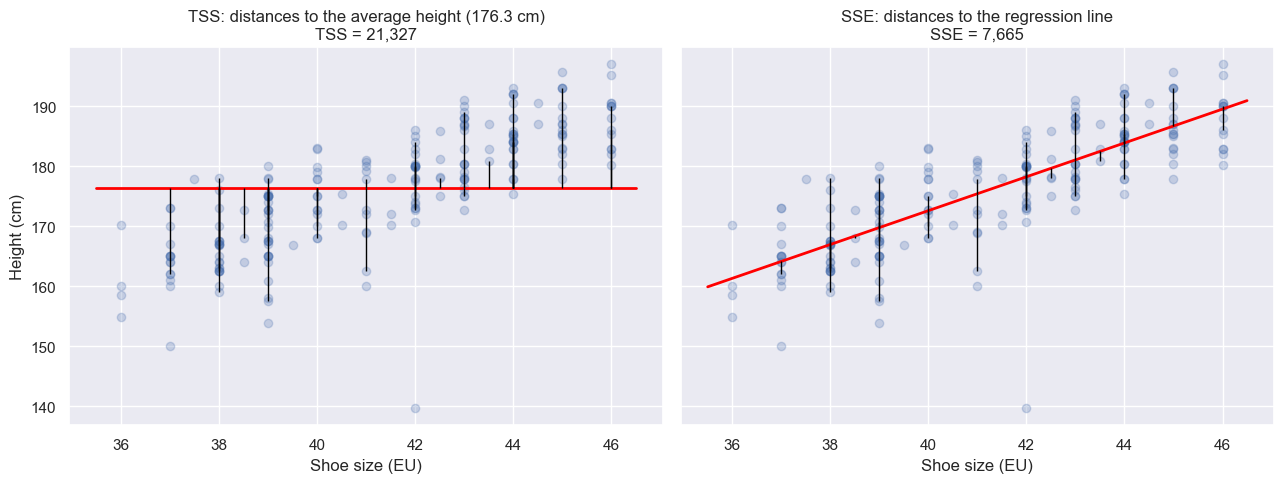

In [9]:
# 35 random students, so the black lines stay readable
idx = np.random.default_rng(5).choice(len(df), 35, replace=False)
x_all, y_all = X["shoe_eu"].to_numpy(), y.to_numpy()
xs = np.array([35.5, 46.5])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Left: distances to the flat line at the average height
axes[0].scatter(x_all, y_all, alpha=0.25)
axes[0].plot(xs, [y.mean(), y.mean()], color="red", lw=2)
axes[0].vlines(x_all[idx], y_all[idx], y.mean(), color="black", lw=1)
axes[0].set_title(f"TSS: distances to the average height ({y.mean():.1f} cm)\nTSS = {tss:,.0f}")

# Right: distances to the regression line
axes[1].scatter(x_all, y_all, alpha=0.25)
axes[1].plot(xs, slope * xs + intercept, color="red", lw=2)
axes[1].vlines(x_all[idx], y_all[idx], y_pred[idx], color="black", lw=1)
axes[1].set_title(f"SSE: distances to the regression line\nSSE = {sse:,.0f}")

for ax in axes: ax.set_xlabel("Shoe size (EU)")
axes[0].set_ylabel("Height (cm)")
plt.tight_layout();

In the picture, the **sum of the squared distances** dropped by **64%** when we swapped the **TSS** line for the regression line (**SSE**). The other **36%** of the variation is still unexplained.

On the right, the black lines are much shorter, because the sloped line gets closer to the dots. That shrinking, from 21,327 to 7,665, is exactly what $R^2$ measures:

$$
R^2 = \frac{TSS - SSE}{TSS} = \frac{21\,327 - 7\,665}{21\,327} \approx 0.64
$$

### Regression Evaluation Metrics

**What they do**

Once you have a best-fit line (regression line), we want to judge **how good the model's predictions are**, meaning whether the line is useful. The regression always finds the **best** line, the one with the smallest squared residuals. But best among all possible lines can still be a bad line. If shoe size and height had no relationship at all, you'd still get a "best" line, and it would predict poorly.

You have a residual for every student. A list of 222 residuals is hard to judge, so a metric summarises it. The metrics answer questions the line can't answer about itself:

| Name | Application |
|---|---|
| **MAE** (**M**ean **A**bsolute **E**rror) | "On average, predictions are off by X" in the **same unit** as y (cm). **Lower values** indicate better model accuracy. |
| **MSE** (**M**ean **S**quared **E**rror) | **MSE = SSE / number of students.** Unit is squared (cm²). |
| **RMSE** (**R**oot **M**ean **S**quared **E**rror) | MSE brought **back to the original unit** (cm). Typical error, with big misses weighted more than in MAE. |
| **R²** (coefficient of determination) | How much better the model is than **always guessing the average**. From 0 (no better) to 1 (perfect). |

**R² = 0.64 means: shoe size explains about 64% of the variation in height.**

**How to get them in code.** scikit-learn has a function for each one in `sklearn.metrics`. Each takes the actual values and the predictions. RMSE has no function of its own here, so it is the square root of the MSE.

In [10]:
# The four metrics, from the actual heights and the model's predictions
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"MAE  = {mae:.1f} cm    (average miss)")
print(f"MSE  = {mse:.1f} cm^2 (average squared miss)")
print(f"RMSE = {rmse:.1f} cm    (square root of MSE)")
print(f"R^2  = {r2:.2f}       (share of the variation explained)")

MAE  = 4.4 cm    (average miss)
MSE  = 34.5 cm^2 (average squared miss)
RMSE = 5.9 cm    (square root of MSE)
R^2  = 0.64       (share of the variation explained)


The same numbers calculated by hand from the residuals, to show that there is no magic in them:

In [11]:
# By hand, from the residuals
print("MAE  =", round(residuals.abs().mean(), 1), "  (average of the misses, sign ignored)")
print("MSE  =", round((residuals ** 2).mean(), 1), "  (average of the squared misses = SSE / number of students)")
print("RMSE =", round(np.sqrt((residuals ** 2).mean()), 1))
print("R^2  =", round(1 - sse / tss, 2), "  (1 - SSE / TSS)")

# A shortcut: the fitted model can also report R^2 itself
print("model.score(X, y) =", round(model.score(X, y), 2))

MAE  = 4.4   (average of the misses, sign ignored)
MSE  = 34.5   (average of the squared misses = SSE / number of students)
RMSE = 5.9
R^2  = 0.64   (1 - SSE / TSS)
model.score(X, y) = 0.64


**Is the model better than just guessing the average?** A *baseline* answers that: a model that always predicts the average height. `DummyRegressor` builds it in the same way as the real model, so the two can be compared directly.

In [12]:
# The lazy model: always predict the average height
baseline = DummyRegressor(strategy="mean").fit(X, y)
baseline_pred = baseline.predict(X)

# Metrics of both models side by side
pd.DataFrame({
    "Always guess the average": [mean_absolute_error(y, baseline_pred), mean_squared_error(y, baseline_pred), r2_score(y, baseline_pred)],
    "Regression line": [mae, mse, r2],
}, index=["MAE (cm)", "MSE (cm^2)", "R^2"]).round(2)

,Always guess the average,Regression line
MAE (cm),8.05,4.37
MSE (cm^2),96.07,34.53
R^2,0.00,0.64


#### Judging on unseen students (train/test split)

The numbers above were measured on the same students the line was fitted to, which is a bit optimistic. The usual fix is to **split** the data: fit the line on a training part and score it on a test part the model has never seen.

In [13]:
# 80% of the students to fit the line, 20% kept aside for testing (random_state makes the split repeatable)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "training students and", len(X_test), "test students")

# Fit on the training part only
model_split = LinearRegression().fit(X_train, y_train)

# Score on both parts
def report(name, y_true, y_hat):
    return {"set": name, "MAE (cm)": mean_absolute_error(y_true, y_hat), "RMSE (cm)": np.sqrt(mean_squared_error(y_true, y_hat)), "R^2": r2_score(y_true, y_hat)}

pd.DataFrame([report("train", y_train, model_split.predict(X_train)),
              report("test", y_test, model_split.predict(X_test))]).set_index("set").round(2)

177 training students and 45 test students


,MAE (cm),RMSE (cm),R^2
set,,,
train,4.42,6.05,0.62
test,4.24,5.15,0.72


The test numbers are the honest ones. Here the test and training errors are about the same (MAE 4.2 against 4.4 cm), which means the straight line is not overfitting. The test part is only 45 students, so its numbers jump around: the test R² happens to be higher than the training R² here, which is chance, not a sign that the model is better on new students. With a different `random_state` the values change, because a different set of students ends up in the test part.

## Overfitting and Underfitting

**What is Overfitting?**

The model memorises the training data, including its noise, instead of learning the general pattern. It looks very good on the students it was fitted to, and bad on new students.

**What is Underfitting?**

The model is too simple to capture the pattern, so it does badly on both the training data and new data.

**Rule of thumb:** the more flexible the model, the easier it overfits. A straight line with one input is very hard to overfit. A curve with many bends can chase every dot.

**In code:** a polynomial of a higher degree is a more flexible curve. To make overfitting visible, each model is trained on only 25 students and tested on the others, and the result is averaged over 20 different random splits.

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

results = []
for degree in [1, 2, 5]:
    train_err, test_err = [], []
    for seed in range(20):
        # Only 25 students for training, all the others for testing
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=25, random_state=seed)
        # Scale the input, create the polynomial terms, then fit a straight line to them
        m = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression()).fit(X_tr, y_tr)
        train_err.append(mean_absolute_error(y_tr, m.predict(X_tr)))
        test_err.append(mean_absolute_error(y_te, m.predict(X_te)))
    results.append({"degree": degree, "MAE on training students": np.mean(train_err), "MAE on new students": np.mean(test_err)})

pd.DataFrame(results).set_index("degree").round(2)

,MAE on training students,MAE on new students
degree,,
1,4.59,4.49
2,4.49,4.68
5,4.13,6.05


**How to read the table:** at degree 1 (the straight line) the training and new-student errors are about the same. At degree 5 the error on the training students gets *lower*, but the error on new students gets *higher*. That gap between the two is the sign of overfitting.

The flat line (the lazy baseline) is the opposite case: it underfits, with a large error on both.

### Correlation vs Causation

A strong correlation says that two variables move together. It does not say that one causes the other. Shoe size does not make anyone taller: both are linked to something else, like sex and body size.

For a regression with one input, $R^2$ is simply the correlation $r$ squared.

In [15]:
# The correlation between shoe size and height, and its square
r = df["shoe_eu"].corr(df["height_cm"])
print(f"correlation r = {r:.2f}")
print(f"r squared     = {r**2:.2f}   (the same as R^2 = {r2_score(y, y_pred):.2f})")

correlation r = 0.80
r squared     = 0.64   (the same as R^2 = 0.64)
